In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageFile
from collections import Counter
from tqdm.auto import tqdm
from pathlib import Path

ImageFile.LOAD_TRUNCATED_IMAGES = False

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

# Change this path if thy ZIP is stored elsewhere
zip_path = "/content/drive/MyDrive/cell_images.zip"

# Expected extracted dataset path
dataset_path = "/content/malaria_dataset/cell_images"

print("ZIP exists:", os.path.exists(zip_path))
print("Dataset folder exists:", os.path.exists(dataset_path))


Mounted at /content/drive
ZIP exists: True
Dataset folder exists: False


In [ ]:
import zipfile

if not os.path.exists(dataset_path):
    os.makedirs("/content/malaria_dataset", exist_ok=True)

    if os.path.exists(zip_path):
        with zipfile.ZipFile(zip_path, "r") as z:
            z.extractall("/content/malaria_dataset")
        print("Extraction completed.")
    else:
        raise FileNotFoundError(
            f"ZIP not found at {zip_path}. Please correct zip_path."
        )

print("Extraction directory:", "/content/malaria_dataset")


Extraction completed.
Extraction directory: /content/malaria_dataset


In [ ]:
for root, dirs, files in os.walk("/content/malaria_dataset"):
    depth = root.replace("/content/malaria_dataset", "").count(os.sep)

    if depth <= 3:
        print(
            "  " * depth,
            os.path.basename(root) or root,
            f"| {len(files)} files"
        )


 malaria_dataset | 0 files
   cell_images | 0 files
     Parasitized | 13780 files
     Uninfected | 13780 files


In [ ]:

from pathlib import Path

dataset_path = Path("/content/malaria_dataset/cell_images")

class_names = ["Parasitized", "Uninfected"]
image_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

if not dataset_path.exists():
    raise FileNotFoundError(f"Dataset folder not found: {dataset_path}")

class_counts = {}

for class_name in class_names:
    class_dir = dataset_path / class_name

    if not class_dir.exists():
        print(f"WARNING: Missing folder: {class_dir}")
        continue

    images = [
        p for p in class_dir.iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    ]

    class_counts[class_name] = len(images)
    print(f"{class_name}: {len(images):,} images")

print("\nTotal images:", sum(class_counts.values()))



Parasitized: 13,779 images
Uninfected: 13,779 images

Total images: 27558


,Class,Image Count,Percentage
0,Parasitized,13779,50.0
1,Uninfected,13779,50.0


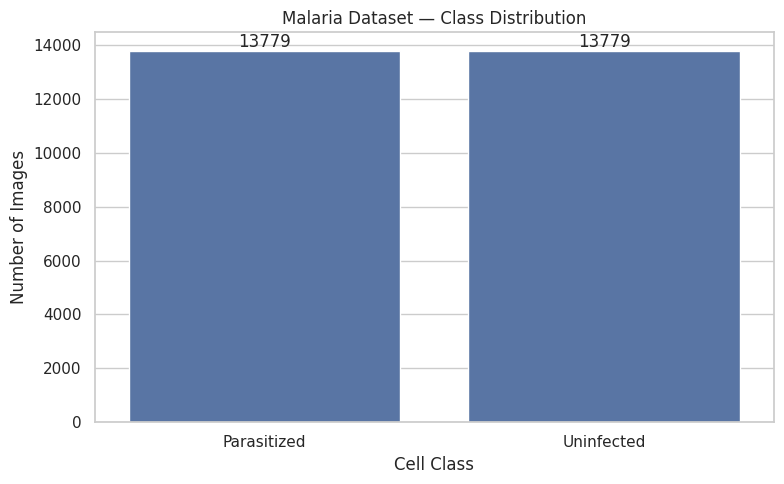

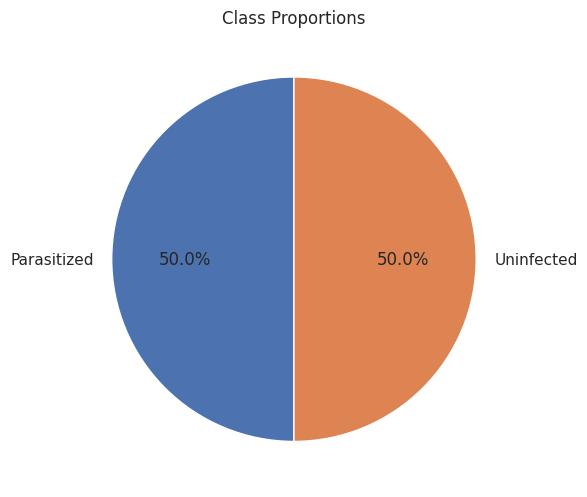

Class imbalance ratio: 1.000


In [ ]:

if not class_counts or sum(class_counts.values()) == 0:
    raise ValueError("No images found. Verify the dataset path and folders.")

counts_df = pd.DataFrame({
    "Class": list(class_counts.keys()),
    "Image Count": list(class_counts.values())
})

counts_df["Percentage"] = (
    counts_df["Image Count"] / counts_df["Image Count"].sum() * 100
)

display(counts_df)

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=counts_df, x="Class", y="Image Count")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.title("Malaria Dataset — Class Distribution")
plt.xlabel("Cell Class")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 6))
plt.pie(
    counts_df["Image Count"],
    labels=counts_df["Class"],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Class Proportions")
plt.tight_layout()
plt.show()

imbalance_ratio = (
    max(class_counts.values()) / min(class_counts.values())
    if min(class_counts.values()) > 0 else np.inf
)

print(f"Class imbalance ratio: {imbalance_ratio:.3f}")


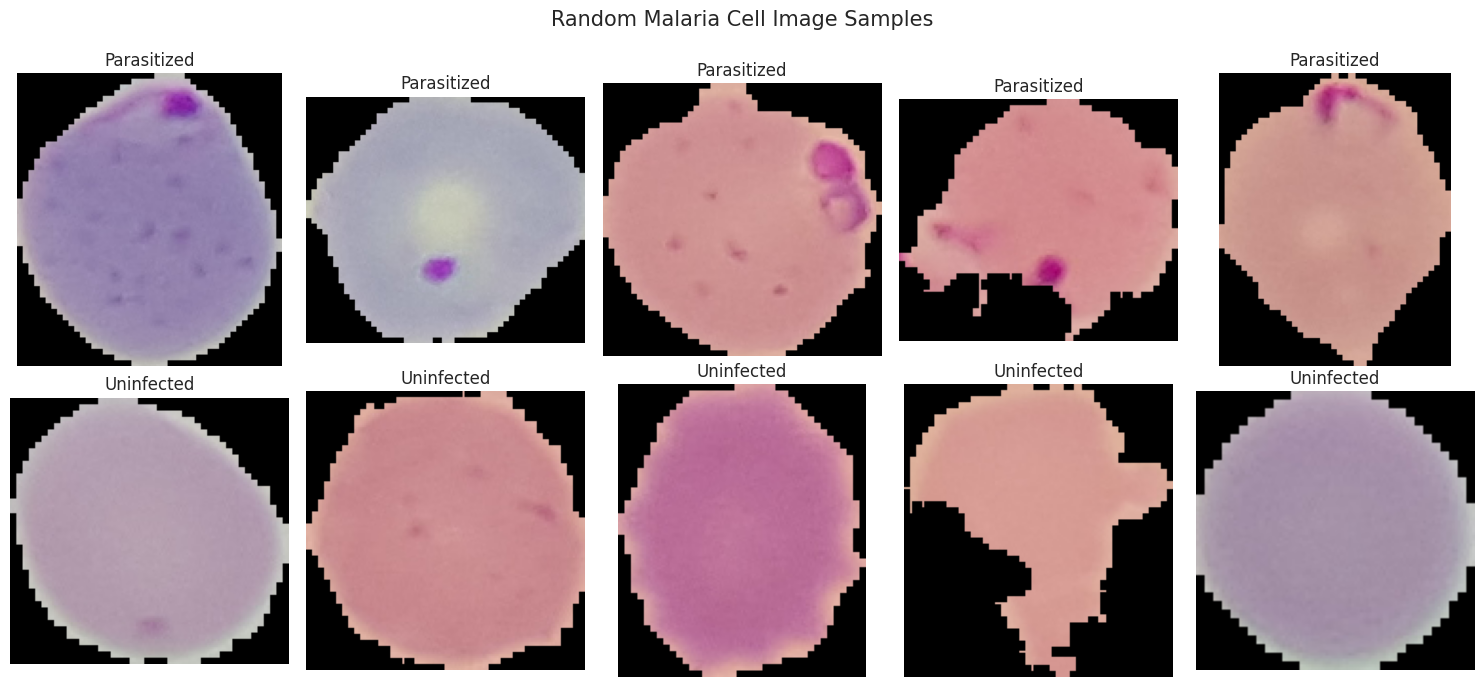

In [ ]:

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for row, class_name in enumerate(class_names):
    class_dir = dataset_path / class_name

    if not class_dir.exists():
        continue

    files = [
        p for p in class_dir.iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    ]

    selected = random.sample(files, min(5, len(files)))

    for col, img_path in enumerate(selected):
        with Image.open(img_path) as img:
            axes[row, col].imshow(img.convert("RGB"))
            axes[row, col].set_title(class_name)
            axes[row, col].axis("off")

    for col in range(len(selected), 5):
        axes[row, col].axis("off")

plt.suptitle("Random Malaria Cell Image Samples", fontsize=15)
plt.tight_layout()
plt.show()


Reading Parasitized dimensions:   0%|          | 0/13779 [00:00<?, ?it/s]

Reading Uninfected dimensions:   0%|          | 0/13779 [00:00<?, ?it/s]

,filename,class,width,height,aspect_ratio,mode,format
0,C139P100ThinF_IMG_20151005_183521_cell_154.png,Parasitized,166,199,0.834171,RGB,PNG
1,C136P97ThinF_IMG_20151005_140538_cell_114.png,Parasitized,142,106,1.339623,RGB,PNG
2,C140P101ThinF_IMG_20151005_210026_cell_180.png,Parasitized,133,139,0.956835,RGB,PNG
3,C132P93ThinF_IMG_20151004_152808_cell_48.png,Parasitized,121,136,0.889706,RGB,PNG
4,C172P133ThinF_IMG_20151119_155307_cell_261.png,Parasitized,133,178,0.747191,RGB,PNG
5,C99P60ThinF_IMG_20150918_140900_cell_106.png,Parasitized,196,166,1.180723,RGB,PNG
6,C136P97ThinF_IMG_20151005_142627_cell_7.png,Parasitized,124,124,1.000000,RGB,PNG
7,C68P29N_ThinF_IMG_20150819_134504_cell_136.png,Parasitized,232,160,1.450000,RGB,PNG
8,C68P29N_ThinF_IMG_20150819_134712_cell_2.png,Parasitized,154,130,1.184615,RGB,PNG
9,C132P93ThinF_IMG_20151004_153030_cell_28.png,Parasitized,136,115,1.182609,RGB,PNG



Dimension summary:


,width,height,aspect_ratio
count,27558.000000,27558.000000,27558.000000
mean,132.487154,132.983453,1.007259
std,20.015949,20.619650,0.147196
min,46.000000,40.000000,0.457831
25%,121.000000,121.000000,0.920530
50%,130.000000,130.000000,1.000000
75%,142.000000,145.000000,1.081081
max,394.000000,385.000000,2.594937



Most common dimensions:


,width,height,count
633,130,130,224
590,127,124,200
592,127,130,199
547,124,124,191
548,124,127,187
713,136,130,184
634,130,133,179
632,130,127,177
546,124,121,172
502,121,121,170


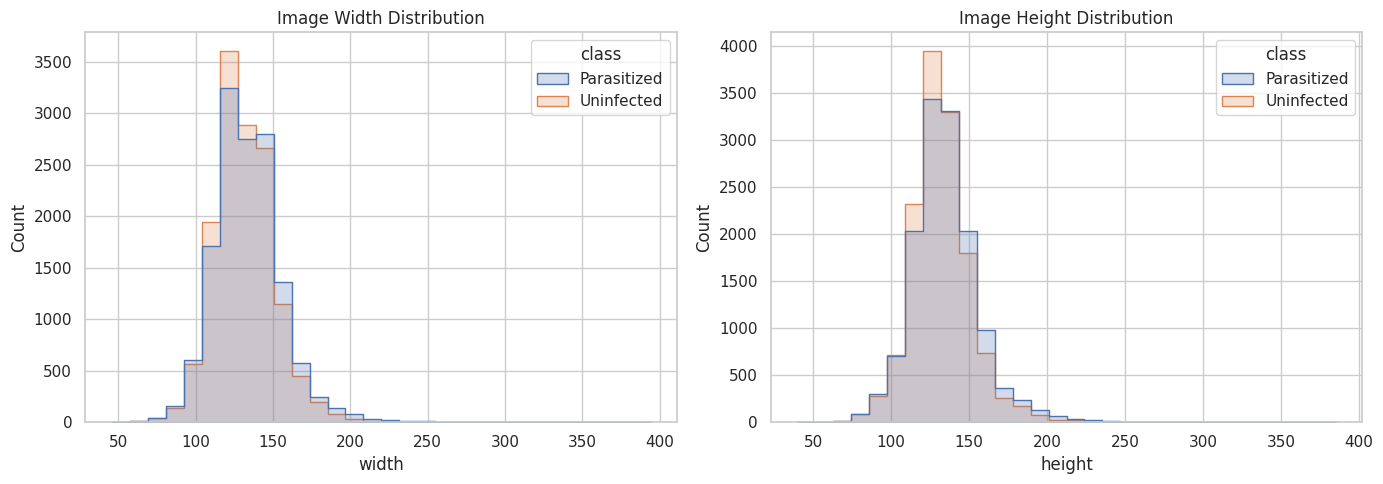

In [ ]:

dimension_records = []

for class_name in class_names:
    class_dir = dataset_path / class_name

    if not class_dir.exists():
        continue

    files = [
        p for p in class_dir.iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    ]

    for img_path in tqdm(files, desc=f"Reading {class_name} dimensions"):
        try:
            with Image.open(img_path) as img:
                width, height = img.size

                dimension_records.append({
                    "filename": img_path.name,
                    "class": class_name,
                    "width": width,
                    "height": height,
                    "aspect_ratio": width / height,
                    "mode": img.mode,
                    "format": img.format
                })
        except Exception:
            pass

dimensions_df = pd.DataFrame(dimension_records)

if not dimensions_df.empty:
    display(dimensions_df.head(10))
    print("\nDimension summary:")
    display(dimensions_df[["width", "height", "aspect_ratio"]].describe())

    print("\nMost common dimensions:")
    display(
        dimensions_df.groupby(["width", "height"])
        .size()
        .reset_index(name="count")
        .sort_values("count", ascending=False)
        .head(15)
    )

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sns.histplot(
        data=dimensions_df, x="width", hue="class",
        bins=30, ax=axes[0], element="step"
    )
    axes[0].set_title("Image Width Distribution")

    sns.histplot(
        data=dimensions_df, x="height", hue="class",
        bins=30, ax=axes[1], element="step"
    )
    axes[1].set_title("Image Height Distribution")

    plt.tight_layout()
    plt.show()
else:
    print("No readable image dimensions were collected.")


In [ ]:

corrupt_records = []
checked_count = 0

for class_name in class_names:
    class_dir = dataset_path / class_name

    if not class_dir.exists():
        continue

    files = [
        p for p in class_dir.iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    ]

    for img_path in tqdm(files, desc=f"Validating {class_name}"):
        checked_count += 1

        try:
            with Image.open(img_path) as img:
                img.verify()
            with Image.open(img_path) as img:
                img.load()

        except Exception as e:
            corrupt_records.append({
                "filename": str(img_path),
                "class": class_name,
                "error": str(e)
            })

corrupt_df = pd.DataFrame(corrupt_records)

print("Images checked:", checked_count)
print("Unreadable images:", len(corrupt_df))
print(
    "Unreadable percentage:",
    round(100 * len(corrupt_df) / checked_count, 4)
    if checked_count else 0,
    "%"
)

if not corrupt_df.empty:
    display(corrupt_df.head(20))


Validating Parasitized:   0%|          | 0/13779 [00:00<?, ?it/s]

Validating Uninfected:   0%|          | 0/13779 [00:00<?, ?it/s]

Images checked: 27558
Unreadable images: 0
Unreadable percentage: 0.0 %


Sampling pixels: Parasitized:   0%|          | 0/200 [00:00<?, ?it/s]

Sampling pixels: Uninfected:   0%|          | 0/200 [00:00<?, ?it/s]

,R_mean,G_mean,B_mean,overall_mean,overall_std
class,,,,,
Parasitized,0.528810,0.410450,0.440201,0.459820,0.304351
Uninfected,0.539452,0.449309,0.468680,0.485813,0.303290


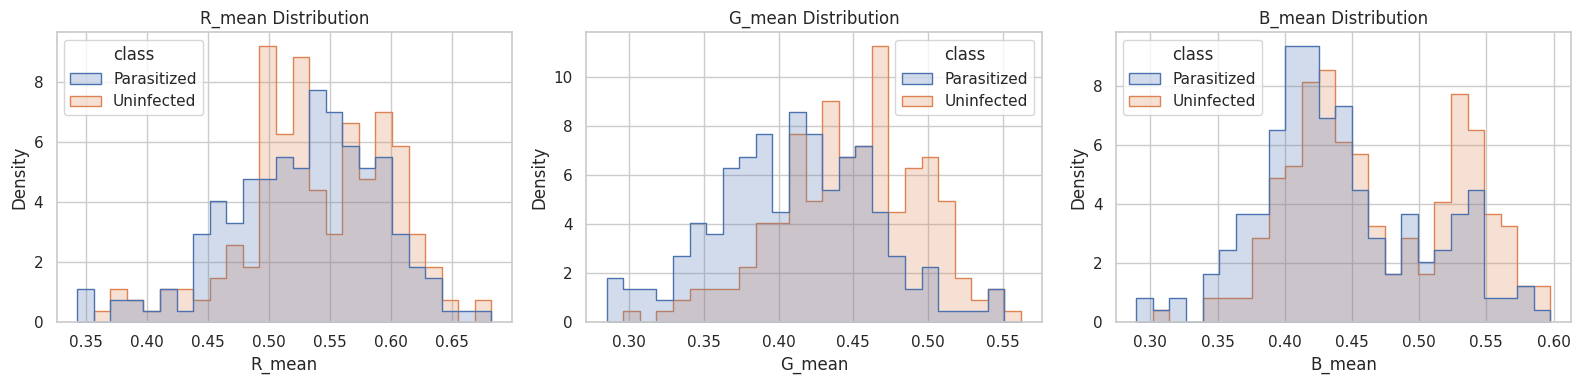

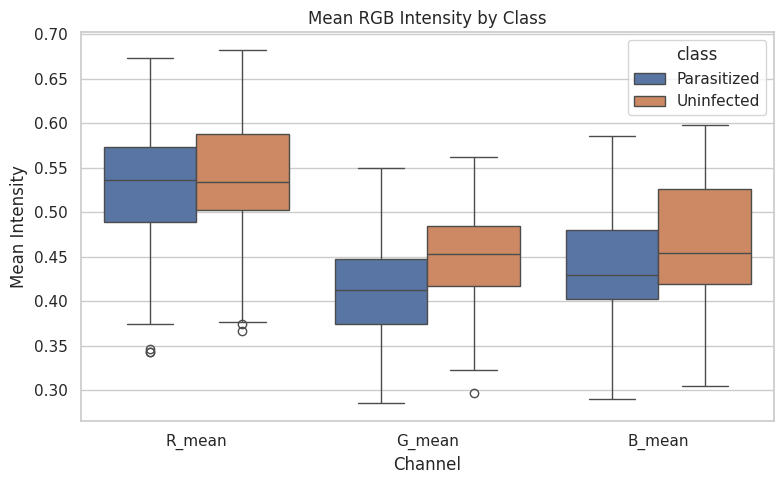

In [ ]:

pixel_records = []
sample_per_class = 200

for class_name in class_names:
    class_dir = dataset_path / class_name

    if not class_dir.exists():
        continue

    files = [
        p for p in class_dir.iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    ]

    selected = random.sample(files, min(sample_per_class, len(files)))

    for img_path in tqdm(selected, desc=f"Sampling pixels: {class_name}"):
        try:
            with Image.open(img_path) as img:
                arr = np.asarray(img.convert("RGB"), dtype=np.float32) / 255.0

            pixel_records.append({
                "class": class_name,
                "R_mean": arr[:, :, 0].mean(),
                "G_mean": arr[:, :, 1].mean(),
                "B_mean": arr[:, :, 2].mean(),
                "overall_mean": arr.mean(),
                "overall_std": arr.std()
            })
        except Exception:
            continue

pixel_df = pd.DataFrame(pixel_records)

if not pixel_df.empty:
    display(pixel_df.groupby("class").mean(numeric_only=True))

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    for channel, ax in zip(
        ["R_mean", "G_mean", "B_mean"], axes
    ):
        sns.histplot(
            data=pixel_df, x=channel, hue="class",
            bins=25, element="step", stat="density",
            common_norm=False, ax=ax
        )
        ax.set_title(f"{channel} Distribution")

    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8, 5))
    sns.boxplot(
        data=pixel_df.melt(
            id_vars="class",
            value_vars=["R_mean", "G_mean", "B_mean"],
            var_name="Channel",
            value_name="Mean Intensity"
        ),
        x="Channel", y="Mean Intensity", hue="class"
    )
    plt.title("Mean RGB Intensity by Class")
    plt.tight_layout()
    plt.show()


Grayscale: Parasitized:   0%|          | 0/200 [00:00<?, ?it/s]

Grayscale: Uninfected:   0%|          | 0/200 [00:00<?, ?it/s]

mean_intensity                                                    \
                     count      mean       std       min       25%       50%   
class                                                                          
Parasitized          200.0  0.444818  0.045786  0.238829  0.418506  0.447595   
Uninfected           200.0  0.477849  0.037185  0.374445  0.456132  0.480891   

                                std_intensity            ... min_intensity  \
                  75%       max         count      mean  ...           75%   
class                                                    ...                 
Parasitized  0.475657  0.546752         200.0  0.286415  ...           0.0   
Uninfected   0.501638  0.568049         200.0  0.291227  ...           0.0   

                 max_intensity                                          \
             max         count      mean       std       min       25%   
class                                                                    
Parasitized  0.0         200.0  0.772608  0.032957  0.674510  0.749020   
Uninfected   0.0         200.0  0.772608  0.037552  0.627451  0.748039   

                                           
                  50%       75%       max  
class                                      
Parasitized  0.768627  0.793137  0.874510  
Uninfected   0.768627  0.796078  0.878431  

[2 rows x 32 columns]

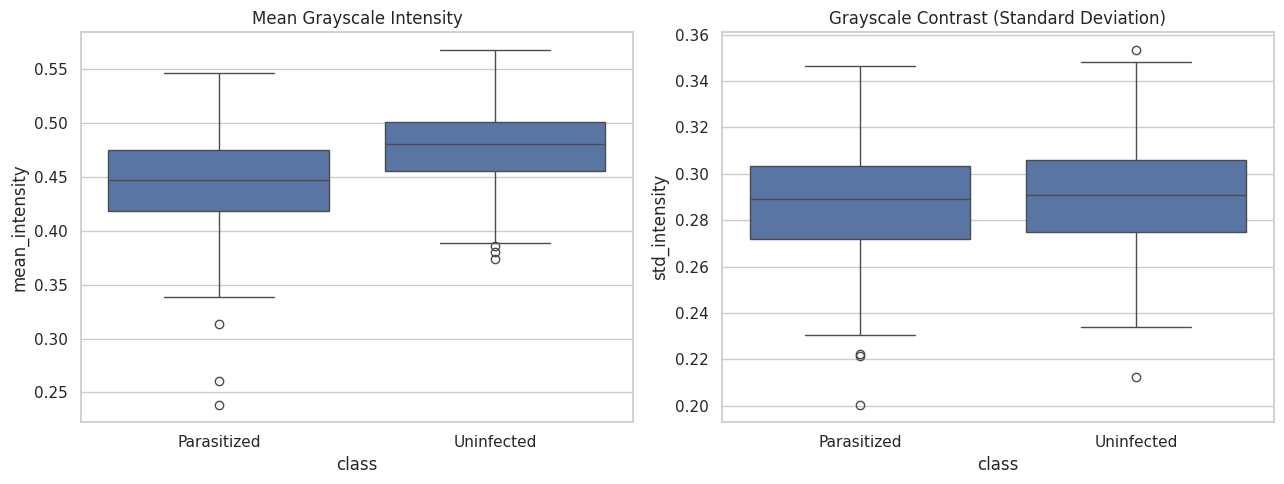

In [ ]:

gray_records = []
sample_per_class = 200

for class_name in class_names:
    class_dir = dataset_path / class_name

    if not class_dir.exists():
        continue

    files = [
        p for p in class_dir.iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    ]

    selected = random.sample(files, min(sample_per_class, len(files)))

    for img_path in tqdm(selected, desc=f"Grayscale: {class_name}"):
        try:
            with Image.open(img_path) as img:
                gray = np.asarray(img.convert("L"), dtype=np.float32) / 255.0

            gray_records.append({
                "class": class_name,
                "mean_intensity": gray.mean(),
                "std_intensity": gray.std(),
                "min_intensity": gray.min(),
                "max_intensity": gray.max()
            })
        except Exception:
            continue

gray_df = pd.DataFrame(gray_records)

if not gray_df.empty:
    display(gray_df.groupby("class").describe())

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    sns.boxplot(
        data=gray_df, x="class", y="mean_intensity", ax=axes[0]
    )
    axes[0].set_title("Mean Grayscale Intensity")

    sns.boxplot(
        data=gray_df, x="class", y="std_intensity", ax=axes[1]
    )
    axes[1].set_title("Grayscale Contrast (Standard Deviation)")

    plt.tight_layout()
    plt.show()


In [ ]:

if not dimensions_df.empty:
    print("Image color modes:")
    display(
        dimensions_df.groupby(["class", "mode"])
        .size()
        .reset_index(name="count")
        .sort_values("count", ascending=False)
    )

    print("\nFile formats:")
    display(
        dimensions_df.groupby(["class", "format"])
        .size()
        .reset_index(name="count")
    )


Image color modes:


,class,mode,count
0,Parasitized,RGB,13779
1,Uninfected,RGB,13779



File formats:


,class,format,count
0,Parasitized,PNG,13779
1,Uninfected,PNG,13779


In [ ]:

import hashlib

hash_records = []

for class_name in class_names:
    class_dir = dataset_path / class_name

    if not class_dir.exists():
        continue

    files = [
        p for p in class_dir.iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    ]

    for img_path in tqdm(files, desc=f"Hashing {class_name}"):
        try:
            digest = hashlib.sha256(img_path.read_bytes()).hexdigest()

            hash_records.append({
                "filename": str(img_path),
                "class": class_name,
                "sha256": digest
            })
        except Exception:
            continue

hash_df = pd.DataFrame(hash_records)

if not hash_df.empty:
    duplicate_mask = hash_df.duplicated("sha256", keep=False)
    duplicates_df = hash_df[duplicate_mask].sort_values("sha256")

    print("Exact duplicate files:", int(duplicate_mask.sum()))
    print("Unique duplicate groups:", duplicates_df["sha256"].nunique())

    if not duplicates_df.empty:
        display(duplicates_df.head(50))
    class_counts_per_hash = hash_df.groupby("sha256")["class"].nunique()
    conflicting_hashes = class_counts_per_hash[class_counts_per_hash > 1]

    print("Hashes appearing in multiple classes:", len(conflicting_hashes))


Hashing Parasitized:   0%|          | 0/13779 [00:00<?, ?it/s]

Hashing Uninfected:   0%|          | 0/13779 [00:00<?, ?it/s]

Exact duplicate files: 0
Unique duplicate groups: 0
Hashes appearing in multiple classes: 0


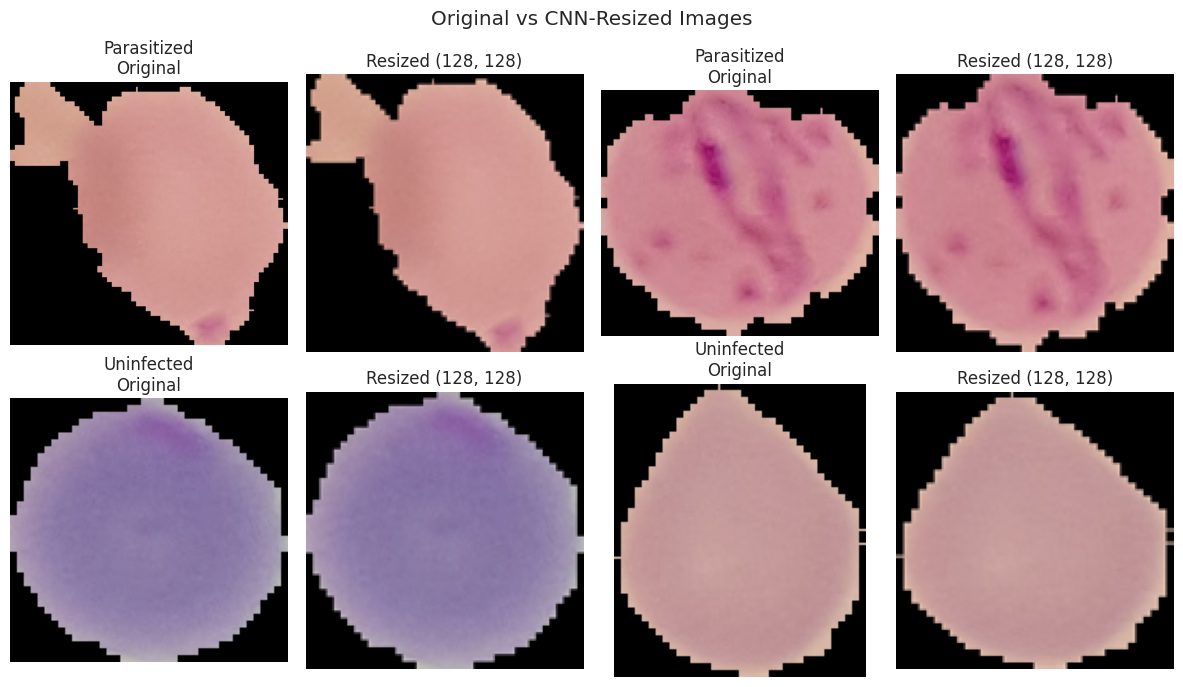

In [ ]:

IMG_SIZE = (128, 128)

fig, axes = plt.subplots(2, 4, figsize=(12, 7))

for row, class_name in enumerate(class_names):
    class_dir = dataset_path / class_name

    if not class_dir.exists():
        continue

    files = [
        p for p in class_dir.iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    ]

    selected = random.sample(files, min(2, len(files)))

    for col, img_path in enumerate(selected):
        with Image.open(img_path) as img:
            original = img.convert("RGB")
            resized = original.resize(IMG_SIZE)

        axes[row, col * 2].imshow(original)
        axes[row, col * 2].set_title(f"{class_name}\nOriginal")
        axes[row, col * 2].axis("off")

        axes[row, col * 2 + 1].imshow(resized)
        axes[row, col * 2 + 1].set_title(f"Resized {IMG_SIZE}")
        axes[row, col * 2 + 1].axis("off")

plt.suptitle("Original vs CNN-Resized Images")
plt.tight_layout()
plt.show()


In [ ]:

output_dir = Path("/content/malaria_eda_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

counts_df.to_csv(output_dir / "class_distribution.csv", index=False)

if not dimensions_df.empty:
    dimensions_df.to_csv(
        output_dir / "image_dimensions.csv", index=False
    )

if not corrupt_df.empty:
    corrupt_df.to_csv(
        output_dir / "corrupted_images.csv", index=False
    )

if not pixel_df.empty:
    pixel_df.to_csv(
        output_dir / "pixel_statistics.csv", index=False
    )

if not gray_df.empty:
    gray_df.to_csv(
        output_dir / "grayscale_statistics.csv", index=False
    )

if not hash_df.empty:
    hash_df.to_csv(
        output_dir / "image_hashes.csv", index=False
    )

print("EDA tables saved in:", output_dir)


EDA tables saved in: /content/malaria_eda_outputs
